# Analyze `optuna_search_pruning.py` results

Reads everything downloaded from CARC into `./results/`, plus `best_test_raw.csv`
(from `python evaluate_test.py --outdir results`, run once the winning config is locked in)
and the noise-condition breakdown (`analyze_noise_effect.py`, run inline below).

Unlike the non-pruning run, `optuna_trials.csv` here can contain `PRUNED` trials (via
`WilcoxonPruner`) -- those only scored a partial batch of train series before being cut off,
so their `user_attrs_mean_f1_*` isn't comparable to a `COMPLETE` trial's (which scored the
full train set). The search-space plots below use `COMPLETE` trials only.

**Scope note:** same as the non-pruning notebook -- the search-space comparison
(precision/recall scatter, F1 heatmap) is **train-only**; `best_validation_raw.csv`/
`best_test_raw.csv` only ever score the single winning config.

In [1]:
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from IPython.display import Image, display

RESULTS_DIR = "results"
METHODS_DIR = os.path.abspath("..")   # Methods/ -- for analyze_noise_effect.py
sys.path.insert(0, METHODS_DIR)

with open(os.path.join(RESULTS_DIR, "best_params.json")) as f:
    best_params = json.load(f)
OBJECTIVE = best_params.get("objective", "warming")

trials_df = pd.read_csv(os.path.join(RESULTS_DIR, "optuna_trials.csv"))
conv_df = pd.read_csv(os.path.join(RESULTS_DIR, "optuna_convergence.csv"))
train_df = pd.read_csv(os.path.join(RESULTS_DIR, "best_train_raw.csv"))
val_df = pd.read_csv(os.path.join(RESULTS_DIR, "best_validation_raw.csv"))

test_csv = os.path.join(RESULTS_DIR, "best_test_raw.csv")
test_df = pd.read_csv(test_csv) if os.path.exists(test_csv) else None
if test_df is None:
    print(f"{test_csv} not found -- run `python evaluate_test.py --outdir {RESULTS_DIR}` "
          "first to score the winning config on held-out TEST (one-time; see its docstring).")

print(f"objective optimized: f1_{OBJECTIVE}")
best_params

objective optimized: f1_warming


{'method': 'KernelCPD',
 'cost': 'linear',
 'pen': 18.676148828397857,
 'n_bkps': None,
 'min_size': 5,
 'jump': 1,
 'trial_number': 281,
 'objective': 'warming',
 'train_f1_all': 0.8144547877954089,
 'train_f1_warming': 0.7910645202041913,
 'train_f1_cooling': 0.8403343548352104,
 'train_mean_elapsed_s': 0.013068809848239956,
 'run_metadata': {'wall_time_s': 7478.692118877021,
  'n_trials_this_run': 300,
  'n_trials_total': 300,
  'n_pruned_total': 212,
  'n_failed_total': 0,
  'p_threshold': 0.05,
  'batch_size': 24}}

## Trial states (COMPLETE / PRUNED / FAIL) and convergence

trials total: 300
state
PRUNED      212
COMPLETE     88
Name: count, dtype: int64

pruned fraction: 70.7%


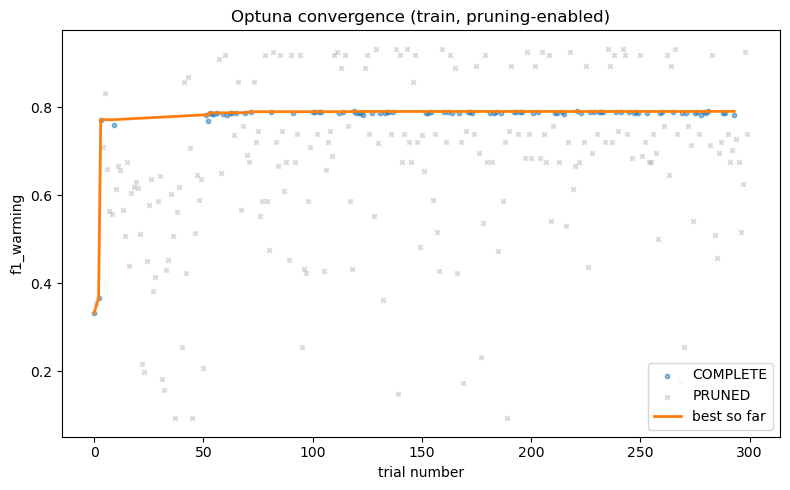

In [2]:
print(f"trials total: {len(trials_df)}")
print(trials_df['state'].value_counts())
print(f"\npruned fraction: {(trials_df['state'] == 'PRUNED').mean():.1%}")

fig, ax = plt.subplots(figsize=(8, 5))
complete = trials_df[trials_df['state'] == 'COMPLETE'].sort_values('number')
pruned = trials_df[trials_df['state'] == 'PRUNED'].sort_values('number')
ax.scatter(complete['number'], complete['value'], s=10, alpha=0.5, label='COMPLETE')
ax.scatter(pruned['number'], pruned['value'], s=10, alpha=0.3, color='gray', marker='x', label='PRUNED')
ax.plot(conv_df['number'], conv_df['best_value_so_far'], color='C1', linewidth=2, label='best so far')
ax.set_xlabel('trial number')
ax.set_ylabel(f"f1_{OBJECTIVE}")
ax.set_title('Optuna convergence (train, pruning-enabled)')
ax.legend()
fig.tight_layout()

## Failed / crashed trials

Some trials error out mid-detection (e.g. a worker OOM-crash) and get caught, marked
`FAIL` (or `COMPLETE` with a fallback `value=0.0` if the error handling differs), but
`user_attrs_mean_f1_*` stays `NaN` -- these are why some cells in the plots below can be
entirely blank rather than just low-scoring. Worth checking before reading too much into
any method's absence.

In [3]:
if 'user_attrs_error' in trials_df.columns:
    error_mask = trials_df['user_attrs_error'].notna()
    print(f"{error_mask.sum()} / {len(trials_df)} trials recorded an error")
    if error_mask.any():
        print(trials_df.loc[error_mask, 'user_attrs_error'])
else:
    print(f"0 / {len(trials_df)} trials recorded an error (no error column present — none errored)")

0 / 300 trials recorded an error (no error column present — none errored)


## Search-space overview (train, COMPLETE trials only)

Optuna's grouped/conditional search space stores `cost` and `pen` in per-method columns
(`params_cost_<Method>`, `params_pen_<Method>_<cost>`) that are non-null only for the method
that particular trial actually used. `unify_trial_params` reconstructs a single
`(method, cost, pen)` view, one row per trial. Restricted to `state == 'COMPLETE'` --
`PRUNED` trials only scored part of train, so mixing them in would understate/overstate
some cells depending on which series they happened to see before being cut off.

In [4]:
def unify_trial_params(row):
    method = row.get('params_method')
    if pd.isna(method):
        return pd.Series({'method': np.nan, 'cost': np.nan, 'pen': np.nan})
    cost = row.get(f'params_cost_{method}', np.nan)
    pen = np.nan
    if pd.notna(cost):
        pen = row.get(f'params_pen_{method}_{cost}', np.nan)
    return pd.Series({'method': method, 'cost': cost, 'pen': pen})

unified = trials_df.apply(unify_trial_params, axis=1)
trials_unified = pd.concat([trials_df, unified], axis=1)
trials_unified = trials_unified[trials_unified['state'] == 'COMPLETE'].copy()

trials_unified['train_precision'] = trials_unified[f'user_attrs_mean_precision_{OBJECTIVE}']
trials_unified['train_recall'] = trials_unified[f'user_attrs_mean_recall_{OBJECTIVE}']
trials_unified['train_f1'] = trials_unified[f'user_attrs_mean_f1_{OBJECTIVE}']

METHODS_SEEN = sorted(trials_unified['method'].dropna().unique())
COST_ORDER = sorted(trials_unified['cost'].dropna().unique())
print(f"{len(trials_unified)} COMPLETE trials across {len(METHODS_SEEN)} methods, "
      f"{len(COST_ORDER)} cost functions")
trials_unified['method'].value_counts()

88 COMPLETE trials across 3 methods, 4 cost functions


method
KernelCPD    85
Binseg        2
Pelt          1
Name: count, dtype: int64

In [5]:
# categorical palette: color = cost function, shape = method (independent legends below)
NEUTRAL = "#898781"
COST_PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#4a3aa7",
                "#e34948", "#17becf", "#a0522d", "#cc79a7"]
COST_COLORS = {c: COST_PALETTE[i % len(COST_PALETTE)] for i, c in enumerate(COST_ORDER)}
COST_LABELS = {"l1": r"$\ell_1$", "l2": r"$\ell_2$"}
def cost_label(c):
    return COST_LABELS.get(c, c)

MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]
METHOD_MARKERS = {m: MARKERS[i % len(MARKERS)] for i, m in enumerate(METHODS_SEEN)}

SEQUENTIAL_BLUE = LinearSegmentedColormap.from_list("seq_blue", [
    "#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

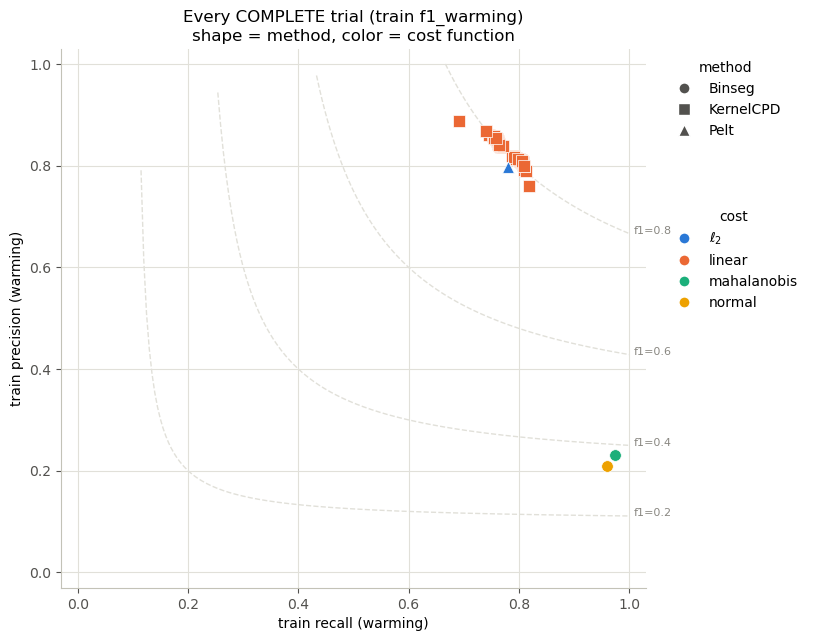

In [6]:
def plot_precision_recall(df, methods, costs, markers, colors, objective):
    fig, ax = plt.subplots(figsize=(9.5, 7))

    r = np.linspace(0.01, 1, 200)
    for f1_target in [0.2, 0.4, 0.6, 0.8]:
        with np.errstate(divide="ignore", invalid="ignore"):
            p = f1_target * r / (2 * r - f1_target)
        mask = (p > 0) & (p <= 1)
        ax.plot(r[mask], p[mask], color="#e1e0d9", linewidth=1, linestyle="--", zorder=0)
        if mask.any():
            xi = np.where(mask)[0][-1]
            ax.annotate(f"f1={f1_target}", (r[xi], p[xi]), color="#898781", fontsize=8,
                        xytext=(3, 0), textcoords="offset points")

    for method in methods:
        for cost in costs:
            sub = df[(df["method"] == method) & (df["cost"] == cost) & (df["train_f1"] > 0)]
            if sub.empty:
                continue
            ax.scatter(sub["train_recall"], sub["train_precision"],
                       color=colors.get(cost, NEUTRAL), marker=markers.get(method, "o"),
                       s=70, zorder=3, edgecolor="white", linewidth=0.5)

    ax.set_xlabel(f"train recall ({objective})")
    ax.set_ylabel(f"train precision ({objective})")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.03, 1.03)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_yticks(np.linspace(0, 1, 6))
    ax.set_title(f"Every COMPLETE trial (train f1_{objective})\nshape = method, color = cost function")

    # both legends moved outside the axes (right margin, stacked) instead of
    # "lower left"/"lower right" inside the plot -- those overlapped scatter points and
    # made some entries hard to read, especially where markers cluster near a corner.
    method_handles = [Line2D([0], [0], marker=markers.get(m, "o"), linestyle="none",
                              markerfacecolor="#52514e", markeredgecolor="white",
                              markersize=8, label=m) for m in methods]
    cost_handles = [Line2D([0], [0], marker="o", linestyle="none",
                            markerfacecolor=colors.get(c, NEUTRAL), markeredgecolor="white",
                            markersize=8, label=cost_label(c)) for c in costs]
    method_legend = ax.legend(handles=method_handles, title="method", frameon=False,
                               loc="upper left", bbox_to_anchor=(1.02, 1.0))
    ax.add_artist(method_legend)
    ax.legend(handles=cost_handles, title="cost", frameon=False,
              loc="upper left", bbox_to_anchor=(1.02, 1.0 - 0.055 * (len(methods) + 2)))

    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#c3c2b7")
    ax.grid(color="#e1e0d9", linewidth=0.8, zorder=0)
    ax.set_axisbelow(True)
    ax.tick_params(colors="#52514e")
    fig.subplots_adjust(right=0.74)   # reserve room for the legends outside the axes
    return fig

fig = plot_precision_recall(trials_unified, METHODS_SEEN, COST_ORDER, METHOD_MARKERS, COST_COLORS, OBJECTIVE)
plt.show()

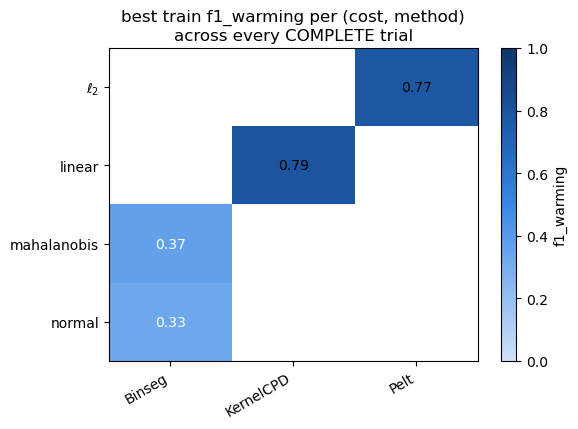

In [7]:
def plot_f1_heatmap(df, methods, costs, objective):
    # best-over-grid per (cost, method) cell -- each cell can hide several pen/min_size
    # trials for that combo; take the best one, same "conclusion" semantics as the old
    # pre-Optuna grid search's per-method conclusion.csv.
    best_per_cell = df.groupby(['cost', 'method'])['train_f1'].max().reset_index()
    pivot = best_per_cell.pivot(index='cost', columns='method', values='train_f1')
    pivot = pivot.reindex(index=[c for c in costs if c in pivot.index],
                           columns=[m for m in methods if m in pivot.columns])

    fig, ax = plt.subplots(figsize=(1.3 * len(pivot.columns) + 2, 0.6 * len(pivot.index) + 2))
    im = ax.imshow(pivot.values, cmap=SEQUENTIAL_BLUE, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(pivot.columns)))
    ax.set_xticklabels(pivot.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(pivot.index)))
    ax.set_yticklabels([cost_label(c) for c in pivot.index])
    ax.set_title(f"best train f1_{objective} per (cost, method)\nacross every COMPLETE trial")
    for i in range(pivot.shape[0]):
        for j in range(pivot.shape[1]):
            val = pivot.values[i, j]
            if pd.notna(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center",
                        color="white" if val < 0.6 else "black")
    fig.colorbar(im, ax=ax, label=f"f1_{objective}")
    fig.tight_layout()
    return fig

fig = plot_f1_heatmap(trials_unified, METHODS_SEEN, COST_ORDER, OBJECTIVE)
plt.show()

## Winning config: train vs. validation vs. test

Per-series breakdown for the single winning config, split by direction (`all` / `warming` / `cooling`).

In [8]:
metric_cols = [c for c in train_df.columns if c.startswith(('precision_', 'recall_', 'f1_'))]

summary_data = {'train_mean': train_df[metric_cols].mean(), 'val_mean': val_df[metric_cols].mean()}
if test_df is not None:
    summary_data['test_mean'] = test_df[metric_cols].mean()
summary = pd.DataFrame(summary_data)
summary

,train_mean,val_mean,test_mean
precision_all,0.847343,0.854208,0.839792
recall_all,0.810780,0.847189,0.806329
f1_all,0.814455,0.838181,0.821371
precision_warming,0.810123,0.795354,0.790948
recall_warming,0.804778,0.833929,0.797063
f1_warming,0.791065,0.798815,0.792496
precision_cooling,0.891788,0.926270,0.897973
recall_cooling,0.816989,0.860630,0.816162
f1_cooling,0.840334,0.882663,0.852626


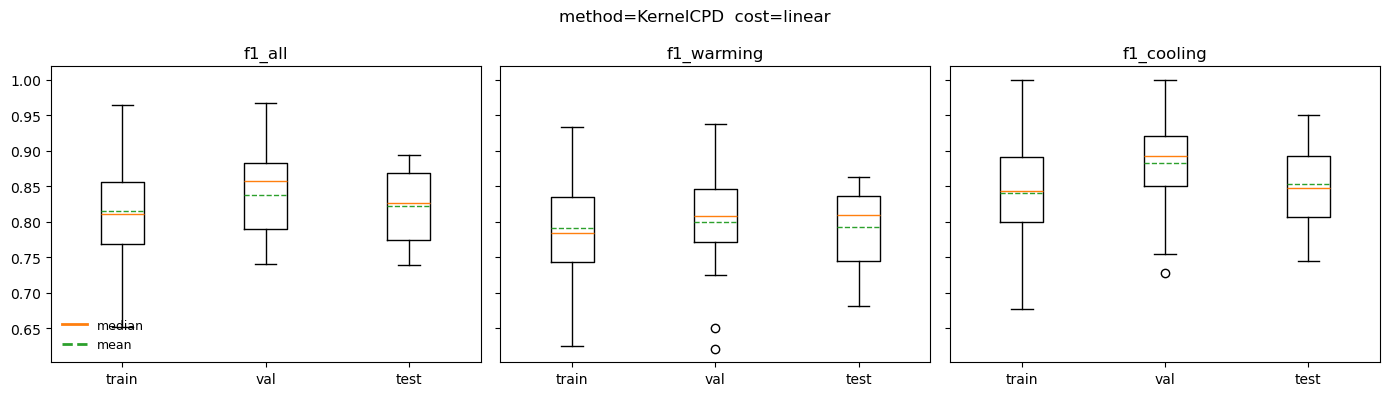

In [9]:
splits = [('train', train_df), ('val', val_df)] + ([('test', test_df)] if test_df is not None else [])

fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, label in zip(axes, ('all', 'warming', 'cooling')):
    ax.boxplot(
        [df[f'f1_{label}'].dropna() for _, df in splits],
        tick_labels=[name for name, _ in splits],
        showmeans=True, meanline=True,   # mean as a dashed line (default color C2) instead of a marker
    )
    ax.set_title(f'f1_{label}')

# boxplot draws the median as a solid line (matplotlib's default 'C1' orange) and, with
# showmeans=True, meanline=True, the mean as a dashed line (default 'C2' green) --
# neither gets an automatic legend entry, so build one explicitly to avoid mixing them up.
median_handle = Line2D([0], [0], color='C1', linewidth=2, linestyle='-', label='median')
mean_handle = Line2D([0], [0], color='C2', linewidth=2, linestyle='--', label='mean')
axes[0].legend(handles=[median_handle, mean_handle], loc='lower left', frameon=False, fontsize=9)

fig.suptitle(f"method={best_params.get('method')}  cost={best_params.get('cost')}")
fig.tight_layout()

## Noise-condition effect (winning config)

The original motivating question for this whole project: how does noise **color**
(white/pink/red) and **level** (SNR) change detection performance? Reuses
`analyze_noise_effect.py` (unchanged) to join each split's per-seed scores against
`train_test_split_data/{split}_manifest.csv` by row position, then plots a color x level
heatmap. Same single-winning-config caveat as above -- this is not a method/cost sweep.

In [10]:
from analyze_noise_effect import load_merged, summarize_all_splits, plot_heatmap_row, DEFAULT_DATA_DIR, NOISIER_DATA_DIR

# precision/recall alongside f1 -- f1 can hide whether a config's failures lean toward
# missed transitions (low recall) or false alarms (low precision), which can matter more
# than f1 alone depending on the application (e.g. test is often where recall gets a
# closer look, since that's what a downstream user actually feels).
METRICS = [f'precision_{OBJECTIVE}', f'recall_{OBJECTIVE}', f'f1_{OBJECTIVE}']

# Loaded once here, reused by the three metric cells below (precision / recall / f1) --
# each one gets its own combined table (train/validation/test side by side) plus a single
# figure with all three splits' heatmaps next to each other, same style as the
# non-pruning notebook (../optuna_search/analyze_results.ipynb).
MERGED_BY_SPLIT = {}
for split in ['train', 'validation', 'test']:
    merged = load_merged(RESULTS_DIR, NOISIER_DATA_DIR, split)
    if merged is None:
        print(f"[{split}] best_{split}_raw.csv not found -- skipping")
    MERGED_BY_SPLIT[split] = merged

=== precision_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
red   snr2  0.847 0.152     9      0.783 0.152     3 0.832 0.073     3
      snr4  0.846 0.107     6      0.778 0.185     2 0.794 0.128     2
white snr2  0.845 0.093     7      0.909 0.038     3 0.834 0.060     3
      snr4  0.824 0.171     7      0.849 0.032     2 0.797 0.094     2
      snr3  0.805 0.126     6      0.831 0.093     2 0.783 0.097     2
pink  snr3  0.804 0.110     6      0.681 0.256     2 0.763 0.083     2
red   snr3  0.795 0.135     7      0.732 0.143     2 0.757 0.037     2
pink  snr4  0.770 0.172     6      0.804 0.095     2 0.805 0.019     2
      snr2  0.732 0.154     6      0.741 0.084     2 0.712 0.137     2


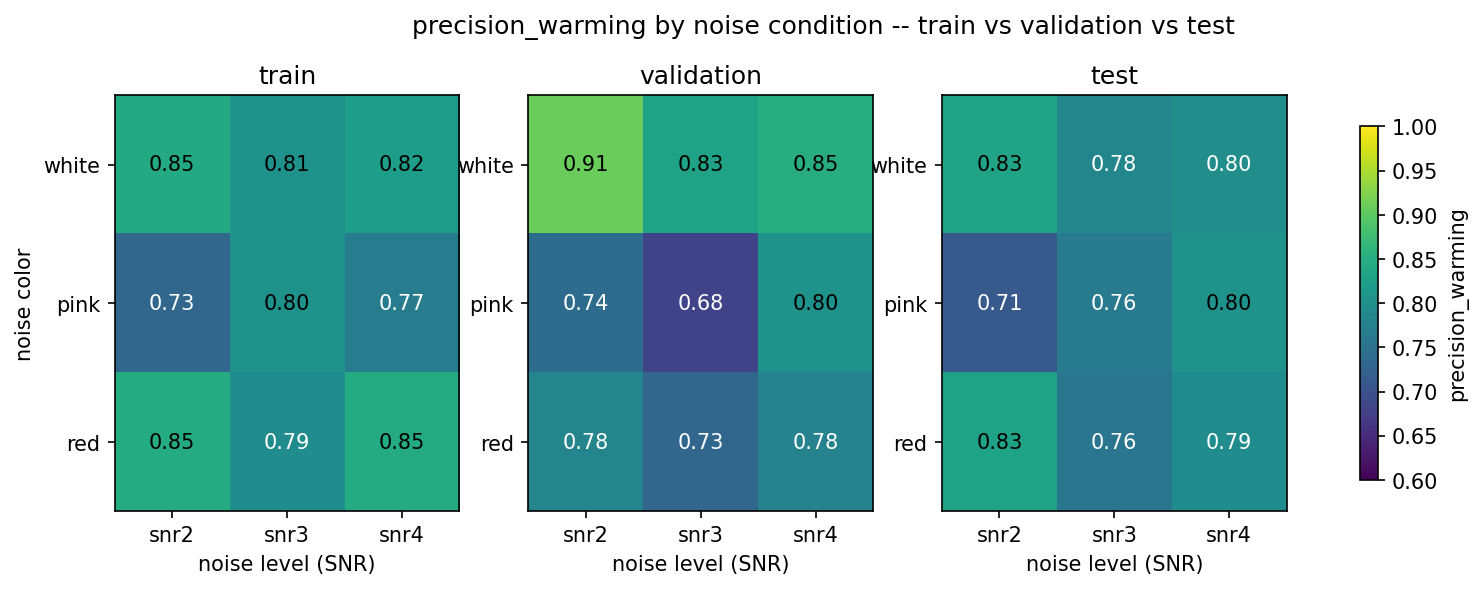

In [11]:
metric = METRICS[0]   # precision_{OBJECTIVE}
print(f"=== {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))
heatmap_path = plot_heatmap_row(MERGED_BY_SPLIT, metric, RESULTS_DIR)
if heatmap_path:
    display(Image(filename=heatmap_path))

=== recall_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
pink  snr3  0.848 0.159     6      0.722 0.137     2 0.791 0.043     2
white snr4  0.848 0.121     7      0.769 0.133     2 0.812 0.073     2
pink  snr4  0.820 0.181     6      0.822 0.158     2 0.860 0.005     2
red   snr2  0.803 0.126     9      0.741 0.224     3 0.768 0.077     3
white snr2  0.801 0.161     7      0.856 0.134     3 0.785 0.057     3
red   snr4  0.791 0.165     6      0.917 0.118     2 0.791 0.043     2
white snr3  0.787 0.134     6      0.842 0.223     2 0.811 0.015     2
pink  snr2  0.787 0.132     6      0.955 0.064     2 0.767 0.008     2
red   snr3  0.761 0.100     7      0.917 0.118     2 0.809 0.069     2


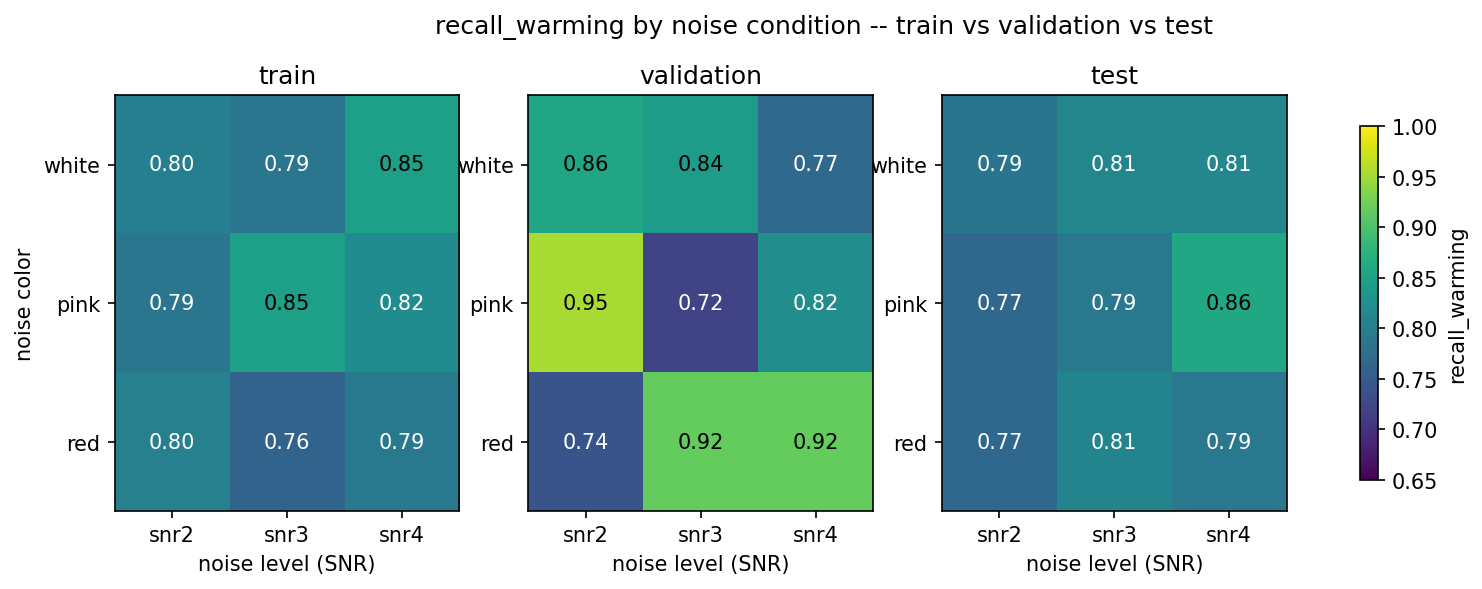

In [12]:
metric = METRICS[1]   # recall_{OBJECTIVE}
print(f"=== {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))
heatmap_path = plot_heatmap_row(MERGED_BY_SPLIT, metric, RESULTS_DIR)
if heatmap_path:
    display(Image(filename=heatmap_path))

=== f1_warming by noise condition -- train vs validation vs test (sorted by train mean) ===
            train             validation              test            
             mean   std count       mean   std count  mean   std count
color level                                                           
white snr4  0.819 0.097     7      0.803 0.059     2 0.804 0.084     2
      snr2  0.811 0.097     7      0.878 0.066     3 0.808 0.054     3
red   snr2  0.810 0.081     9      0.740 0.089     3 0.797 0.061     3
pink  snr3  0.809 0.055     6      0.673 0.074     2 0.776 0.064     2
red   snr4  0.803 0.084     6      0.828 0.059     2 0.791 0.086     2
white snr3  0.782 0.065     6      0.821 0.064     2 0.796 0.058     2
pink  snr4  0.770 0.092     6      0.803 0.029     2 0.832 0.008     2
red   snr3  0.766 0.059     7      0.804 0.042     2 0.782 0.052     2
pink  snr2  0.736 0.046     6      0.831 0.028     2 0.736 0.078     2


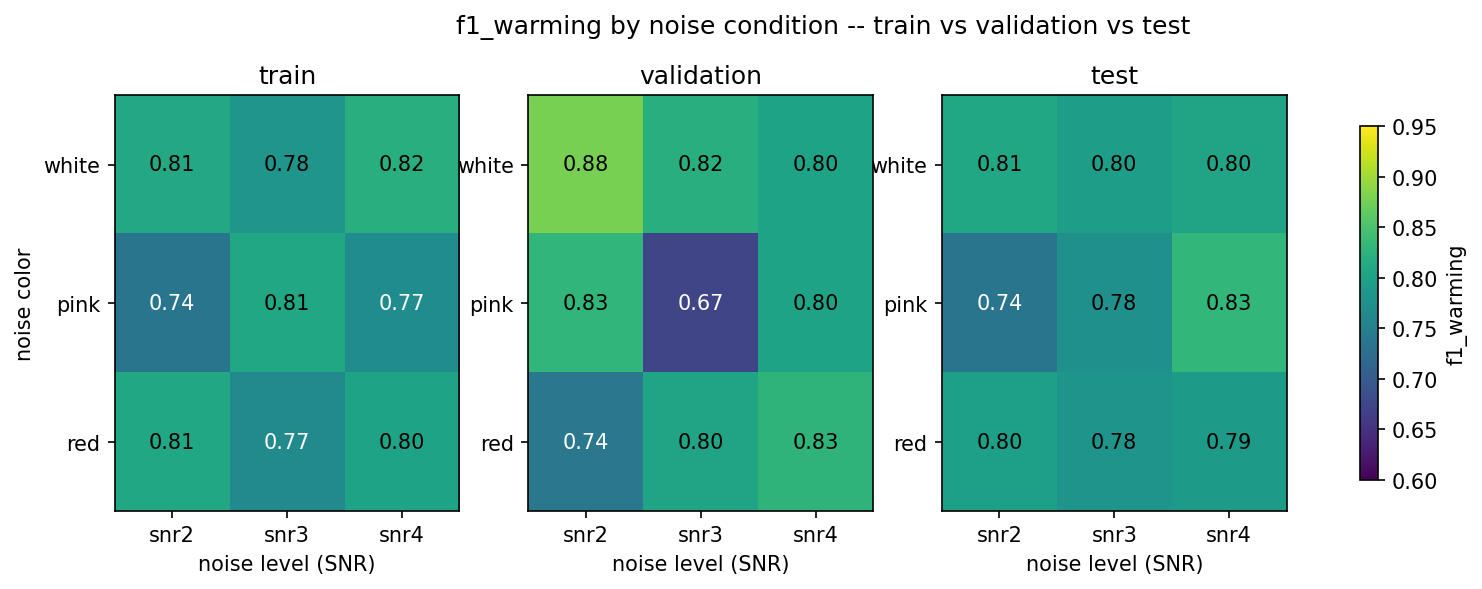

In [13]:
metric = METRICS[2]   # f1_{OBJECTIVE}
print(f"=== {metric} by noise condition -- train vs validation vs test (sorted by train mean) ===")
print(summarize_all_splits(MERGED_BY_SPLIT, metric).to_string(float_format=lambda x: f"{x:.3f}"))
heatmap_path = plot_heatmap_row(MERGED_BY_SPLIT, metric, RESULTS_DIR)
if heatmap_path:
    display(Image(filename=heatmap_path))

## Compare against the non-pruning run

Points at `../optuna_search/results/` to sanity-check that pruning found a comparably
good config in less wall time.

In [14]:
no_prune_path = os.path.join("..", "optuna_search", "results", "best_params.json")
if os.path.exists(no_prune_path):
    with open(no_prune_path) as f:
        no_prune_best = json.load(f)
    compare = pd.DataFrame({
        'pruning': {**best_params, **best_params.get('run_metadata', {})},
        'no_pruning': {**no_prune_best, **no_prune_best.get('run_metadata', {})},
    })
    compare
else:
    print(f"no_prune results not found at {no_prune_path}")

## Applying the winning config to real NGRIP data

Everything above is synthetic (Melcher25 model output, see `Generate_Data_25events.ipynb`).
This section applies the exact same frozen `best_params` (from the pruning run) -- zero re-tuning -- to the real
NGRIP d18O record, scored against the real Dansgaard-Oeschger (DO) event catalog
(`DO_onsets_Rasmussen2014.csv` in ammonyte's data folder: the 25 main GI onsets (one per numbered interstadial) of Rasmussen et al. 2014, Table 2, GICC05modelext (`main25_kyr_b2k`; all 34 are in `all34_kyr_b2k`); it replaces the older `DO_events.csv` `main` column, several of whose entries did not sit at warming onsets), to see how the synthetic-tuned pipeline
performs on the actual real-world series it's ultimately meant for.

**Standardization.** `optuna_search_pruning.py`'s `load_split` standardizes every synthetic training
series independently to zero mean / **unit std** (`pyleoclim.utils.tsutils.standardize`,
default `scale=1`) before `pen` is ever tuned against it -- see that function's docstring,
which says explicitly that this is what lets the tuned params transfer to NGRIP at all,
*because NGRIP gets self-standardized the same way at application time*. So the correct
transfer here is NGRIP standardized to its own zero-mean/unit-std (`ngrip_win.standardize()`,
no `scale` argument) -- not rescaled to match the synthetic pool's raw (unstandardized) std.
Below we compare **raw** (NGRIP's own untouched scale, kept only for contrast) against
**standardized** (NGRIP self-standardized to std=1 -- the actual apples-to-apples setting
`pen` was tuned under).

**Warming only.** Optuna optimized `f1_warming`, and the DO onset catalog only lists warming
transitions -- there's no real cooling ground truth to score against. So detections are
classified by direction (`_classify_detected_directions`, this project's own classifier --
see that function's/`ruptures_transitions.py`'s docstring for why it's not the same as
ammonyte's own `jump_values` up/down sign convention) and only the warming-classified ones
are scored or plotted below, for both the raw-scale and standardized-scale NGRIP runs. An
"all directions" number is deliberately not reported -- it would be comparing detections
against ground truth that doesn't exist for the non-warming ones.

**Direction / orientation.** NGRIP's axis is age (kyr b2k), i.e. backwards in time, whereas the synthetic
data (and the classifier and optimization built on it) run forward in time. So NGRIP is first
time-reversed into forward time (next cell), after which the *unchanged* classifier is used as on the
synthetic splits. This is equivalent to ammonyte's own age-axis `jump_values == 1` convention (checked:
100% agreement for KS and KernelCPD). Detected times and DO events are then expressed in `-kyr b2k`.

In [15]:
import ammonyte as amt
from ammonyte.utils.metrics import evaluate_detection

# Reuse optuna_search_pruning.py's own direction classifier + tolerance constant, so the
# "warming" numbers below stay byte-for-byte consistent with how every synthetic split
# was scored (this project deliberately does NOT use ammonyte's own ruptures_transitions.py
# jump_values sign convention for direction -- see that file's module docstring).
sys.path.insert(0, os.path.join(METHODS_DIR, "optuna_search_pruning"))
from optuna_search_pruning import _classify_detected_directions, TOLERANCE

# Ammonyte ships its own copy of NGRIP.csv/DO_events.csv (verified byte-identical to this
# repo's data/ copy) plus a Series.from_csv loader -- use those directly instead of
# re-parsing the CSV by hand.
AMMONYTE_DATA_DIR = os.path.join(os.path.dirname(amt.__file__), "data")
ngrip_series = amt.Series.from_csv(os.path.join(AMMONYTE_DATA_DIR, "NGRIP.csv"))

# 25 main events = one onset per numbered interstadial (GI-1 ... GI-25), taking the OLDEST sub-event where an
# interstadial is split (e.g. GI-2.2 not GI-2.1), i.e. the onset of the whole interstadial.
do_df = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")
do_gt_times = np.sort(do_df["main25_kyr_b2k"].dropna().values.astype(float))
do_gt_age = do_gt_times.copy()   # catalog ages (kyr b2k); never rebound, so cells can be re-run safely

print(f"NGRIP ({ngrip_series.value_name}, {ngrip_series.time_unit}): {len(ngrip_series.time)} points, "
      f"{ngrip_series.time.min():.2f}-{ngrip_series.time.max():.2f} kyr b2k")
print(f"DO events (warming only): {len(do_gt_times)}, "
      f"{do_gt_times.min():.2f}-{do_gt_times.max():.2f} kyr b2k")

Time axis values sorted in ascending order
Time axis values sorted in ascending order
NGRIP (δ¹⁸O, kyr b2k): 6112 points, 0.05-122.27 kyr b2k
DO events (warming only): 25, 14.69-115.37 kyr b2k


In [16]:
WINDOW_PADDING_KYR = 2.0   # the DO catalog only covers events within its own min/max --
                            # outside that window there's no ground truth at all, so any
                            # detection there is neither confirmably right nor wrong.

# ammonyte's Series inherits pyleoclim's .slice() -- use it instead of manual boolean masking.
ngrip_win = ngrip_series.slice([do_gt_age.min() - WINDOW_PADDING_KYR,
                                 do_gt_age.max() + WINDOW_PADDING_KYR])
print(f"Sliced to DO-catalog window [{ngrip_win.time.min():.2f}, {ngrip_win.time.max():.2f}] kyr "
      f"({WINDOW_PADDING_KYR} kyr padding): {len(ngrip_win.time)} points")

print(f"\nraw NGRIP: mean={ngrip_win.value.mean():.3f}  std={ngrip_win.value.std():.3f} "
      f"(untouched scale -- NOT what pen was tuned against, kept below only for contrast)")

# NGRIP is standardized (zero mean, unit std, like the synthetic series) in the forward-time cell below.


Sliced to DO-catalog window [12.71, 117.37] kyr (2.0 kyr padding): 5234 points

raw NGRIP: mean=-40.705  std=2.383 (untouched scale -- NOT what pen was tuned against, kept below only for contrast)


**Forward-time orientation (same as the synthetic data).** NGRIP's axis is *age* (kyr b2k, ascending =
going back in time), while every synthetic series runs forward in time (higher = warmer, warming = the
value going *up* through the array), which is the convention `_classify_detected_directions` and the
whole optimization assume. So before detection, NGRIP is time-reversed: `time_fwd = -age` (ascending,
i.e. negative kyr before present) with the values reversed, and the DO catalog times are mapped the same
way (`-age`). Detection, tolerance (0.5 kyr) and the unmodified direction classifier are then used
exactly as on the synthetic splits, with no sign flip anywhere. Detected times below are therefore
in `-kyr b2k`.

In [17]:
# Rebuild the age-axis window from the ORIGINAL objects every time, so this cell (and the ones above it) can be
# re-run in any order without flipping the series twice, then rebind the names every downstream cell uses.
ngrip_win_age = ngrip_series.slice([do_gt_age.min() - WINDOW_PADDING_KYR, do_gt_age.max() + WINDOW_PADDING_KYR])

def to_forward_time(series):
    """age-ascending Series -> forward-time Series (time = -age ascending, values reversed)"""
    return amt.Series(time=-series.time[::-1], value=series.value[::-1],
                      time_name="time (forward)", time_unit="-kyr b2k",
                      value_name=series.value_name, value_unit=series.value_unit,
                      label=f"{series.label} (forward time)", verbose=False)

ngrip_win = to_forward_time(ngrip_win_age)
ngrip_standardized_series = ngrip_win.standardize()
do_gt_times = np.sort(-do_gt_age)

print(f"forward NGRIP: {ngrip_win.time.min():.2f} to {ngrip_win.time.max():.2f} (-kyr b2k), "
      f"std of standardized = {ngrip_standardized_series.value.std():.3f}")
import collections
gt_dirs = _classify_detected_directions(ngrip_standardized_series.value, ngrip_standardized_series.time, do_gt_times, 9)
print("original (unflipped) classifier on the real DO onsets:", dict(collections.Counter(gt_dirs)))

forward NGRIP: -117.37 to -12.71 (-kyr b2k), std of standardized = 1.000
original (unflipped) classifier on the real DO onsets: {'warming': 25}


In [18]:
from ammonyte.core.transitions import DeterministicTransitions

NGRIP_UNFILTERED = {}   # label -> in-range detections before direction filtering (see below)

def score_ngrip(series, gt_times, algo, cost, pen, n_bkps, min_size, jump, tolerance, label):
    # series.ruptures(...) is ammonyte's own Series method -- returns a DeterministicTransitions
    # object. Run on the PADDED series (ngrip_win/ngrip_standardized_series) so the detector has
    # real context right at the edges of the labeled region -- but see the filter right below
    # before this gets scored.
    transitions = series.ruptures(algo=algo, cost=cost, pen=pen, n_bkps=n_bkps,
                                   min_size=min_size, jump=jump)
    detected_all = np.asarray(transitions.jump_times, dtype=float)

    # Score only detections INSIDE the labeled range [gt_times.min(), gt_times.max()] --
    # WINDOW_PADDING_KYR's whole purpose was giving the detector edge context, not expanding
    # what gets judged. Scoring the padding zone too would count anything detected there as a
    # false positive purely for being >tolerance from the nearest boundary event, even though
    # we have zero ground truth (right or wrong) out there. This is a different, unrelated
    # concept from `tolerance`, which only controls point-matching distance within this range.
    in_range = (detected_all >= gt_times.min()) & (detected_all <= gt_times.max())
    n_dropped = (~in_range).sum()
    detected = detected_all[in_range]

    # Keep only detections OUR classifier calls warming -- see markdown above for why "all
    # directions" isn't reported: the DO onset catalog has no cooling ground truth to compare against.
    # Direction classification uses the full padded series (series.value/series.time) so the
    # before/after windows around near-boundary points aren't starved of context.
    # `series` is NGRIP in FORWARD time (see the time-reversal cell above), the same orientation as
    # the synthetic data, so the original classifier applies unchanged (warming = value goes up).
    det_directions = _classify_detected_directions(series.value, series.time, detected, min_size)
    detected_warming = detected[det_directions == "warming"]
    NGRIP_UNFILTERED[label] = detected   # in-range detections before the direction filter
    print(f"--- {label}: {len(detected_all)} changepoints detected in the padded window, "
          f"{n_dropped} outside the labeled range (dropped before scoring), {len(detected)} in "
          f"range, {len(detected_warming)} classified warming (scored below) ---")

    # evaluate_detection's own DetectionMetrics.__str__ prints ammonyte's formatted
    # precision/recall/F1 + true/false positive/negative tables.
    warming_metrics = evaluate_detection(detected=detected_warming, ground_truth=gt_times,
                                          tolerance=tolerance)
    print(warming_metrics)

    # Fresh warming-only DeterministicTransitions for plotting below -- NOT `transitions` as-is,
    # since that one still holds every in-padding detection under ammonyte's own up/down
    # jump_values sign convention, not our classifier's warming/cooling call.
    warming_transitions = DeterministicTransitions(
        series=series, jump_times=detected_warming, jump_values=np.ones(len(detected_warming)),
        method=transitions.method, method_args=transitions.method_args,
        label=f"{label} (warming only)",
    )

    return warming_transitions, detected_warming, warming_metrics


ngrip_common_kwargs = dict(algo=best_params["method"], cost=best_params["cost"], pen=best_params["pen"],
                            n_bkps=best_params["n_bkps"], min_size=best_params["min_size"],
                            jump=best_params["jump"])

ngrip_raw_transitions, ngrip_raw_detected_warming, ngrip_raw_warming_metrics = score_ngrip(
    ngrip_win, do_gt_times, tolerance=TOLERANCE, label="raw (NGRIP's own untouched scale)",
    **ngrip_common_kwargs)

print()
ngrip_standardized_transitions, ngrip_standardized_detected_warming, ngrip_standardized_warming_metrics = score_ngrip(
    ngrip_standardized_series, do_gt_times, tolerance=TOLERANCE,
    label="standardized (zero mean, unit std -- same scale pen was tuned on)", **ngrip_common_kwargs)

print(f"\nf1_warming: raw={ngrip_raw_warming_metrics.f1_score:.3f}  "
      f"standardized={ngrip_standardized_warming_metrics.f1_score:.3f}")
print("standardized is the methodologically correct comparison -- it's the scale pen was "
      "actually tuned against (see markdown above). raw is kept only to show what happens "
      "without it.")

--- raw (NGRIP's own untouched scale): 81 changepoints detected in the padded window, 3 outside the labeled range (dropped before scoring), 78 in range, 32 classified warming (scored below) ---
Detection Evaluation Metrics
Metrics calculated within tolerance = 0.5

Performance Scores:
+-----------+---------+
| Metric    |   Value |
+===========+=========+
| Precision |  0.7188 |
+-----------+---------+
| Recall    |  0.92   |
+-----------+---------+
| F1 Score  |  0.807  |
+-----------+---------+

Detection Counts:
+-----------------+---------+
| Category        |   Count |
+=================+=========+
| True Positives  |      23 |
+-----------------+---------+
| False Positives |       9 |
+-----------------+---------+
| False Negatives |       2 |
+-----------------+---------+

Summary:
  Detected: 32 | Ground Truth: 25


--- standardized (zero mean, unit std -- same scale pen was tuned on): 26 changepoints detected in the padded window, 1 outside the labeled range (dropped before s

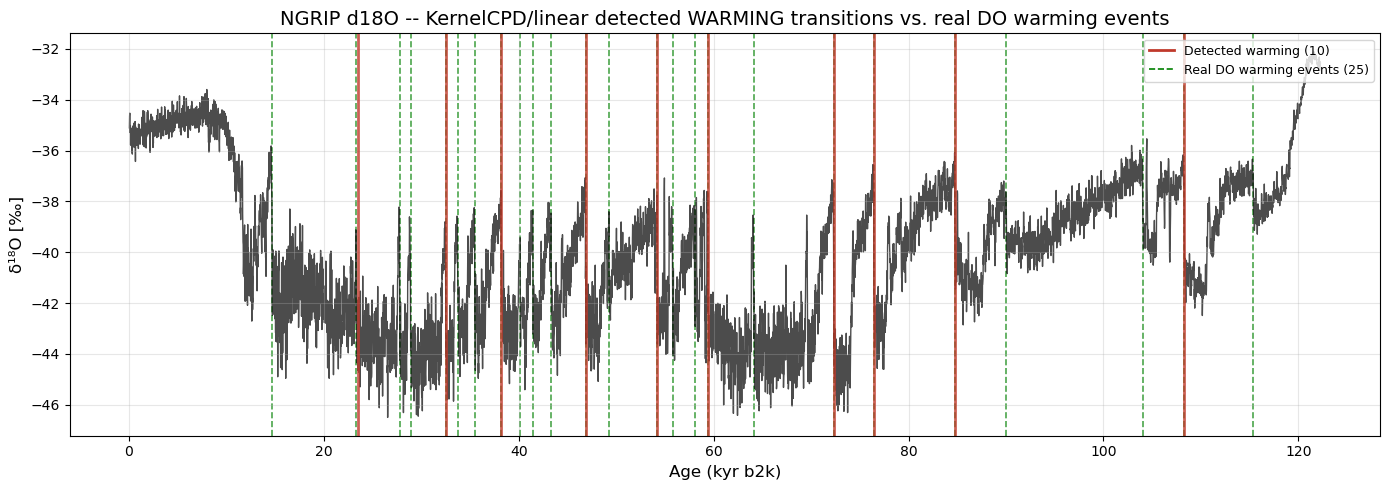

In [19]:
# Detection and direction were computed on the standardized, time-reversed (forward-time) record, but the
# figures show the FULL ORIGINAL NGRIP record (raw d18O in permil, 0-122 kyr) on its usual age axis (kyr b2k, ascending, positive).
# Detections exist only inside the DO-catalog window (the DO-catalog window). Mapping back is just
# age = -time_fwd for the detected times; the DO onsets are already stored as ages (do_gt_age).
def to_age_axis(fwd_transitions, label):
    age_series = ngrip_series           # the FULL original NGRIP record (0-122 kyr b2k, ascending), raw d18O in permil
    ages = np.sort(-np.asarray(fwd_transitions.jump_times, float))
    return DeterministicTransitions(series=age_series, jump_times=ages, jump_values=np.ones(len(ages)),
                                    method=fwd_transitions.method, method_args=fwd_transitions.method_args, label=label)

# warming_transitions (from score_ngrip) already holds ONLY the warming-classified detections
# -- plot with show_transitions="all" (single color, no up/down split) since direction is no
# longer ambiguous at this point. Real DO warming events are overlaid manually (green dashed).
kc_age_transitions = to_age_axis(ngrip_standardized_transitions, "KernelCPD warming (age axis)")
fig, ax = kc_age_transitions.plot(
    figsize=(14, 5), show_transitions="all", transition_color="#c0392b",
    legend_labels=[f"Detected warming ({len(ngrip_standardized_detected_warming)})"],
    title=f"NGRIP d18O -- {best_params['method']}/{best_params['cost']} "
          f"detected WARMING transitions vs. real DO warming events",
)
for t in do_gt_age:
    ax.axvline(t, color="green", linestyle="--", linewidth=1.2, alpha=0.7, zorder=0)
ax.plot([], [], color="green", linestyle="--", linewidth=1.2,
        label=f"Real DO warming events ({len(do_gt_age)})")
ax.set_xlabel("Age (kyr b2k)")
ax.legend(loc="upper right", fontsize=9)
plt.show()

In [20]:
# Side-by-side: synthetic splits (warming-direction metrics) vs. real NGRIP (raw + standardized).
ngrip_comparison = pd.DataFrame({
    'train': [train_df['precision_warming'].mean(), train_df['recall_warming'].mean(),
              train_df['f1_warming'].mean()],
    'validation': [val_df['precision_warming'].mean(), val_df['recall_warming'].mean(),
                   val_df['f1_warming'].mean()],
    'test': ([test_df['precision_warming'].mean(), test_df['recall_warming'].mean(),
              test_df['f1_warming'].mean()] if test_df is not None else [np.nan, np.nan, np.nan]),
    'NGRIP (raw)': [ngrip_raw_warming_metrics.precision, ngrip_raw_warming_metrics.recall,
                     ngrip_raw_warming_metrics.f1_score],
    'NGRIP (standardized)': [ngrip_standardized_warming_metrics.precision,
                              ngrip_standardized_warming_metrics.recall,
                              ngrip_standardized_warming_metrics.f1_score],
}, index=['precision_warming', 'recall_warming', 'f1_warming'])
ngrip_comparison

,train,validation,test,NGRIP (raw),NGRIP (standardized)
precision_warming,0.810123,0.795354,0.790948,0.718750,1.000000
recall_warming,0.804778,0.833929,0.797063,0.920000,0.400000
f1_warming,0.791065,0.798815,0.792496,0.807018,0.571429


## Notes / limitations

- The precision-recall scatter and F1 heatmap use `COMPLETE` trials only -- `PRUNED` trials
  scored only part of train, so are excluded to keep the comparison apples-to-apples.
- `best_validation_raw.csv` / `best_test_raw.csv` only ever hold the single **winning**
  config's per-seed scores, same caveat as the non-pruning notebook.
- Low `count` cells in the noise-condition tables/heatmaps (some conditions have only
  1-3 seeds) mean those means are noisy -- treat single-digit-count cells as suggestive,
  not conclusive.
- NGRIP is scored against `DO_onsets_Rasmussen2014.csv` (the 25 main events, `main25_kyr_b2k`) in forward time; see the diagnostics section at the end for the orientation / direction / standardization checks.


---
# NGRIP diagnostics: orientation, direction labels and standardization (pruning winner)

Same checks as in `../optuna_search/analyze_results.ipynb`, here for the pruning run's winning KernelCPD config:

1. **Orientation.** NGRIP's axis is *age* (kyr b2k, ascending = back in time), so a real warming is the value *decreasing* through the age-ascending array, whereas the synthetic data is forward-time (warming = value goes *up*). Detection/direction are therefore computed on the time-reversed (forward-time) NGRIP, while figures use the original age axis.
2. **Direction routes compared** (per detection): A = old (age array, unmodified classifier), B = negated values, C = reversed forward-time series with the unmodified classifier, D = canonical real-time function, E = by hand from raw d18O (younger-side mean minus older-side mean). B-E should agree on 100% of detections; A (un-reversed) should not.
3. **Real-time check of the hits** under the old and corrected labelling.
4. **Standardization** only rescales the penalty: a raw-scale `pen` equals `pen / std^2` on the standardized scale. Rows with the same effective penalty give identical results.
5. **Catalog.** The DO onsets now come from `DO_onsets_Rasmussen2014.csv` (main scoring uses the 25 main events, `main25_kyr_b2k`; the 34-row table is only used in the catalog-sensitivity check at the end; Rasmussen et al. 2014 Table 2, in ammonyte's data folder), replacing the older `DO_events.csv` `main` column.

Variable names: `ngrip_win_age` = raw NGRIP window on the age axis; `do_gt_age` = catalog ages; `best_params` = this (pruning) winner.

In [21]:
import ruptures as rpt
assert best_params["method"] == "KernelCPD", "the direct ruptures calls below assume KernelCPD"

age = np.asarray(ngrip_win_age.time, float)            # age-ascending, kyr b2k
v_raw = np.asarray(ngrip_win_age.value, float)         # raw d18O (permil)
z = (v_raw - v_raw.mean()) / v_raw.std()               # standardized (same as pyleoclim standardize)
gt_age = np.asarray(do_gt_age, float)
ngrip_std_age = amt.Series(time=age, value=z, verbose=False)

def real_time_change(a, w=0.4):
    """d18O change across an event in REAL time, raw permil: mean(younger side) - mean(older side). >0 = warming."""
    return v_raw[(age >= a - w) & (age < a)].mean() - v_raw[(age >= a) & (age < a + w)].mean()

def canonical_direction(age_arr, val, det_age, min_size, min_window=10):
    """Direction in REAL time, independent of how the array is stored: sort to real-time order first
    (oldest -> youngest), so 'before' is the older side and 'after' the younger side. Same window rule as the
    optimization's classifier: max(min_window, 2*min_size) samples each side, clipped at neighbouring detections.
    Returns labels ordered by ASCENDING age of the detections."""
    order = np.argsort(-age_arr); a = age_arr[order]; x = val[order]
    idxs = np.sort(np.array([int(np.argmin(np.abs(a - t))) for t in det_age]))
    win = max(min_window, 2 * min_size); lab = []
    for k, i in enumerate(idxs):
        bs, ae = max(0, i - win), min(len(x), i + win)
        if k > 0: bs = max(bs, idxs[k - 1])
        if k < len(idxs) - 1: ae = min(ae, idxs[k + 1])
        b, af = x[bs:i], x[i:ae]
        lab.append("warming" if len(b) and len(af) and af.mean() > b.mean() else "cooling")
    return np.array(lab)[::-1]

ms = best_params["min_size"]
tr_kc = ngrip_std_age.ruptures(algo=best_params["method"], cost=best_params["cost"], pen=best_params["pen"],
                               n_bkps=best_params["n_bkps"], min_size=ms, jump=best_params["jump"])
d = np.unique(np.asarray(tr_kc.jump_times, float)); d = d[~np.isnan(d)]
d = np.sort(d[(d >= gt_age.min()) & (d <= gt_age.max())])

A = _classify_detected_directions(z, age, d, ms)                                           # old: age array, unmodified
B = _classify_detected_directions(-z, age, d, ms)                                          # negated values
C_ = _classify_detected_directions(z[::-1], -age[::-1], np.sort(-d), ms)[::-1]             # reversed forward series, unmodified
D_ = canonical_direction(age, z, d, ms)                                                    # canonical real-time
E = np.array(["warming" if real_time_change(a) > 0 else "cooling" for a in d])             # by hand, raw permil
rows = []
for lab, arr in (("A old (age array, unmodified classifier)", A), ("B negated values", B),
                 ("C reversed series, unmodified classifier", C_), ("D canonical real-time function", D_),
                 ("E by hand (raw d18O)", E)):
    w = d[arr == "warming"]
    m = evaluate_detection(detected=w, ground_truth=gt_age, tolerance=TOLERANCE)
    rows.append({"direction route": lab, "in-range detections": len(d), "warming": len(w),
                 "agreement with E": float(np.mean(arr == E)), "hits": m.true_positives,
                 "precision": m.precision, "recall": m.recall, "F1 (warming only)": m.f1_score})
pd.DataFrame(rows).round(3)

,direction route,in-range detections,warming,agreement with E,hits,precision,recall,F1 (warming only)
0,"A old (age array, unmodified classifier)",25,15,0.0,2,0.133,0.08,0.100
1,B negated values,25,10,1.0,10,1.000,0.40,0.571
2,"C reversed series, unmodified classifier",25,10,1.0,10,1.000,0.40,0.571
3,D canonical real-time function,25,10,1.0,10,1.000,0.40,0.571
4,E by hand (raw d18O),25,10,1.0,10,1.000,0.40,0.571


### Real-time check of the hits (standardized NGRIP)

For each detection labelled *warming*: nearest catalog onset, whether it is a hit (within tolerance), and the real-time raw d18O change across it (permil, > 0 = genuine warming).

In [22]:
old_warm = d[A == "warming"]            # OLD labelling
new_warm = d[D_ == "warming"]           # corrected labelling

def hit_table(sel):
    rows = []
    for a in sel:
        j = np.argmin(np.abs(gt_age - a)); dist = abs(gt_age[j] - a); ch = real_time_change(a)
        rows.append({"detected age (kyr b2k)": round(a, 2), "nearest catalog": round(gt_age[j], 2), "dist": round(dist, 2),
                     "hit": dist <= TOLERANCE, "real-time change (permil)": round(ch, 2),
                     "real direction": "warming" if ch > 0 else "COOLING"})
    return pd.DataFrame(rows)

for title, sel in (("OLD labelling (un-reversed)", old_warm), ("CORRECTED labelling", new_warm)):
    t = hit_table(sel); print(f"\n{title}: {len(t)} detections labelled warming, {int(t['hit'].sum())} hits, "
          f"{int(((t['hit']) & (t['real direction'] == 'warming')).sum())} of the hits at genuine warming steps")
    display(t)


OLD labelling (un-reversed): 15 detections labelled warming, 2 hits, 0 of the hits at genuine warming steps


,detected age (kyr b2k),nearest catalog,dist,hit,real-time change (permil),real direction
0,32.05,32.50,0.45,True,-3.08,COOLING
1,33.37,33.74,0.37,True,-3.46,COOLING
2,37.13,38.22,1.09,False,-1.49,COOLING
3,40.93,41.46,0.53,False,-2.75,COOLING
4,45.45,46.86,1.41,False,-1.06,COOLING
5,48.47,49.28,0.81,False,-2.16,COOLING
6,51.67,49.28,2.39,False,-1.14,COOLING
7,56.61,55.80,0.81,False,-1.50,COOLING
8,70.83,72.34,1.51,False,-1.63,COOLING
9,74.19,72.34,1.85,False,-3.19,COOLING



CORRECTED labelling: 10 detections labelled warming, 10 hits, 10 of the hits at genuine warming steps


,detected age (kyr b2k),nearest catalog,dist,hit,real-time change (permil),real direction
0,23.51,23.34,0.17,True,2.13,warming
1,32.51,32.50,0.01,True,3.90,warming
2,38.23,38.22,0.01,True,3.76,warming
3,46.89,46.86,0.03,True,4.31,warming
4,54.23,54.22,0.01,True,3.64,warming
5,59.45,59.44,0.01,True,1.90,warming
6,72.35,72.34,0.01,True,6.17,warming
7,76.45,76.44,0.01,True,5.08,warming
8,84.77,84.76,0.01,True,3.00,warming
9,108.31,108.28,0.03,True,3.94,warming


### Raw vs standardized: same effective penalty gives the same result

Standardizing multiplies the data by `1/std`, so a penalty `p` on the raw scale equals `p / std^2` on the standardized scale. Rows 1=3 and 2=4 must be identical.

In [23]:
sd = v_raw.std(); PEN = best_params["pen"]; J = best_params["jump"]
print(f"NGRIP window raw std = {sd:.3f} permil -> 1 raw pen unit = {1/sd**2:.4f} standardized pen units")

def run_kcpd(x, pen):
    b = np.array(rpt.KernelCPD(kernel="linear", min_size=ms, jump=J).fit(x.reshape(-1, 1)).predict(pen=pen)[:-1])
    dd = np.sort(age[b]); dd = dd[(dd >= gt_age.min()) & (dd <= gt_age.max())]
    ch = np.array([real_time_change(a) for a in dd]); w = dd[ch > 0]          # direction from raw d18O in real time
    mw = evaluate_detection(detected=w, ground_truth=gt_age, tolerance=TOLERANCE)
    ma = evaluate_detection(detected=dd, ground_truth=gt_age, tolerance=TOLERANCE)
    return {"detections": len(dd), "warming": len(w), "cooling": len(dd) - len(w), "warming hits": mw.true_positives,
            "warming P": mw.precision, "warming R": mw.recall, "warming F1": mw.f1_score,
            "no-filter hits": ma.true_positives, "no-filter recall": ma.recall, "no-filter F1": ma.f1_score}

cases = [(f"raw, pen={PEN:.2f}", v_raw, PEN, PEN / sd**2), (f"STANDARDIZED, pen={PEN:.2f} (tuned)", z, PEN, PEN),
         (f"standardized, pen={PEN/sd**2:.2f} (= raw row)", z, PEN / sd**2, PEN / sd**2),
         (f"raw, pen={PEN*sd**2:.1f} (= standardized row)", v_raw, PEN * sd**2, PEN)]
pd.DataFrame([{"case": n, "pen used": p, "effective pen (std units)": e, **run_kcpd(x, p)} for n, x, p, e in cases]).set_index("case").round(3)

NGRIP window raw std = 2.383 permil -> 1 raw pen unit = 0.1762 standardized pen units


,pen used,effective pen (std units),detections,warming,cooling,warming hits,warming P,warming R,warming F1,no-filter hits,no-filter recall,no-filter F1
case,,,,,,,,,,,,
"raw, pen=18.68",18.676,3.290,77,34,43,22,0.647,0.88,0.746,22,0.88,0.431
"STANDARDIZED, pen=18.68 (tuned)",18.676,18.676,25,10,15,10,1.000,0.40,0.571,11,0.44,0.440
"standardized, pen=3.29 (= raw row)",3.290,3.290,77,34,43,22,0.647,0.88,0.746,22,0.88,0.431
"raw, pen=106.0 (= standardized row)",106.017,18.676,25,10,15,10,1.000,0.40,0.571,11,0.44,0.440


### Sensitivity to the penalty (standardized NGRIP, diagnostic only -- not for tuning on NGRIP)

In [24]:
pd.DataFrame([{"pen (standardized)": p, **run_kcpd(z, p)} for p in (PEN, 15, 10, 6, 3.5, 2)]).set_index("pen (standardized)").round(3)

,detections,warming,cooling,warming hits,warming P,warming R,warming F1,no-filter hits,no-filter recall,no-filter F1
pen (standardized),,,,,,,,,,
18.676149,25,10,15,10,1.000,0.40,0.571,11,0.44,0.440
15.000000,33,14,19,14,1.000,0.56,0.718,14,0.56,0.483
10.000000,49,22,27,20,0.909,0.80,0.851,20,0.80,0.541
6.000000,60,27,33,21,0.778,0.84,0.808,21,0.84,0.494
3.500000,76,33,43,22,0.667,0.88,0.759,22,0.88,0.436
2.000000,85,36,49,23,0.639,0.92,0.754,23,0.92,0.418


### Direction-filter sensitivity on NGRIP

Scores **without** any direction filter (all in-range detections vs. all DO onsets). Not strictly apples-to-apples (cooling detections count as false positives), but independent of the classifier.

In [25]:
det_all = NGRIP_UNFILTERED["standardized (zero mean, unit std -- same scale pen was tuned on)"]
m_all = evaluate_detection(detected=det_all, ground_truth=do_gt_times, tolerance=TOLERANCE)
pd.DataFrame({f"{best_params['method']}/{best_params['cost']}": {
    "in-range detections": len(det_all), "F1, no direction filter": m_all.f1_score,
    "precision, no filter": m_all.precision, "recall, no filter": m_all.recall,
    "F1, warming only (forward time)": ngrip_standardized_warming_metrics.f1_score}}).T

,in-range detections,"F1, no direction filter","precision, no filter","recall, no filter","F1, warming only (forward time)"
KernelCPD/linear,25.0,0.44,0.44,0.44,0.571429


### Catalog check: 25 main events vs all 34

The main scoring above uses the **25 main events** (`main25_kyr_b2k`: one onset per numbered interstadial GI-1 ... GI-25). The cell below scores the same detections (this notebook's winning config on standardized NGRIP, real-time direction) against the 25 main events and, for comparison, against all 34 (`all34_kyr_b2k`). The catalog choice does not change what the detector finds, only how hits and misses are counted.


In [26]:
cat_full = pd.read_csv(os.path.join(AMMONYTE_DATA_DIR, "DO_onsets_Rasmussen2014.csv"), comment="#")
catalogs = {
    "25 main events": cat_full.dropna(subset=["main25_kyr_b2k"]).assign(age=lambda d: d["main25_kyr_b2k"]),
    "34 rows (full table)": cat_full.assign(age=lambda d: d["all34_kyr_b2k"]),
}

# detections on standardized NGRIP (age axis), from the winning config; direction in real time (by hand, raw d18O)
det_full = np.unique(np.asarray(tr_kc.jump_times, float)); det_full = det_full[~np.isnan(det_full)]
rows, detail = [], {}
for name, cdf in catalogs.items():
    c = np.sort(cdf["age"].values.astype(float))
    dd = np.sort(det_full[(det_full >= c.min()) & (det_full <= c.max())])
    is_warm = np.array([real_time_change(a) > 0 for a in dd]); w = dd[is_warm]
    mw = evaluate_detection(detected=w, ground_truth=c, tolerance=TOLERANCE)
    ma = evaluate_detection(detected=dd, ground_truth=c, tolerance=TOLERANCE)
    rows.append({"catalog": name, "events": len(c), "detections": len(dd), "warming": len(w), "hits": mw.true_positives,
                 "precision": mw.precision, "recall": mw.recall, "F1 (warming)": mw.f1_score,
                 "F1 (no direction filter)": ma.f1_score})
    detail[name] = (cdf.sort_values("age"), w)
display(pd.DataFrame(rows).set_index("catalog").round(3))

# which of the 25 main events are hit (nearest warming detection)
cdf, w = detail["25 main events"]; out = []
for e, a in zip(cdf["event"], cdf["age"]):
    dist = np.abs(w - a); j = int(np.argmin(dist))
    out.append({"event": e, "age (kyr b2k)": a, "nearest warming detection": round(w[j], 2),
                "distance": round(dist[j], 2), "hit": bool(dist[j] <= TOLERANCE)})
print(f"\n25 main events: {sum(o['hit'] for o in out)} / {len(out)} have a warming detection within {TOLERANCE} kyr")
display(pd.DataFrame(out))


,events,detections,warming,hits,precision,recall,F1 (warming),F1 (no direction filter)
catalog,,,,,,,,
25 main events,25,25,10,10,1.0,0.400,0.571,0.440
34 rows (full table),34,25,10,10,1.0,0.294,0.455,0.373



25 main events: 10 / 25 have a warming detection within 0.5 kyr


,event,age (kyr b2k),nearest warming detection,distance,hit
0,GI-1e,14.692,23.51,8.82,False
1,GI-2.2,23.340,23.51,0.17,True
2,GI-3,27.780,23.51,4.27,False
3,GI-4,28.900,32.51,3.61,False
4,GI-5.2,32.500,32.51,0.01,True
5,GI-6,33.740,32.51,1.23,False
6,GI-7c,35.480,38.23,2.75,False
7,GI-8c,38.220,38.23,0.01,True
8,GI-9,40.160,38.23,1.93,False
9,GI-10,41.460,38.23,3.23,False
